In [1]:
import sys, os, distutils.core
sys.path.insert(0, os.path.abspath('./detectron2'))
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath('./projects/Panoptic-DeepLab/'))
os.environ['DETECTRON2_DATASETS'] = '/home/liwa/data/datasets/'

from detectron2.data import DatasetCatalog, MetadataCatalog
# from oneformer.data.datasets.register_yeast_panoptic_annos_semseg import register_all_yeast_panoptic_annos_sem_seg

/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from run_notebooks.post_process_utils import get_largest_object, convert_to_rgb, segment_slide_window, segment_post_process
from skimage.io import imread, imsave

In [3]:
!pwd

/home/liwa/data/PytrochDeepyeast


In [4]:
from detectron2.config import get_cfg
from detectron2.projects.panoptic_deeplab import (
    PanopticDeeplabDatasetMapper,
    add_panoptic_deeplab_config,
)
from detectron2.engine import default_setup
from detectron2.engine import DefaultPredictor
from prediction import Predictor
from google.colab.patches import cv2_imshow
import os, json, cv2, random
from detectron2.utils.visualizer import Visualizer
import torch

In [5]:
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:8700m"
cfg = get_cfg()
add_panoptic_deeplab_config(cfg)
# add project-specific config (e.g., TensorMask) here if you're not running a model in detectron2's core library
cfg.merge_from_file("/home/liwa/data/PytrochDeepyeast/projects/Panoptic-DeepLab/configs/yeast_panoptics/config.yaml")

cfg.MODEL.DEVICE = "cuda:3"
# into cpu model
# cfg.MODEL.SEM_SEG_HEAD.NORM = "BN"
# cfg.MODEL.INS_EMBED_HEAD.NORM = "BN"
# cfg.MODEL.RESNETS.NORM = "BN"

cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.3 # set threshold for this model

# Find a model from detectron2's model zoo. You can use the https://dl.fbaipublicfiles... url as well
cfg.MODEL.WEIGHTS = os.path.abspath("/home/liwa/data/oneformer_output/output/model_0194999_v5.pth")
# cfg.MODEL.WEIGHTS = "detectron2://DeepLab/R-52.pkl"
# cfg.INPUT.MIN_SIZE_TEST = 512
# cfg.INPUT.MAX_SIZE_TRAIN = 2048

In [6]:
from skimage.io import imread
import numpy as np
from contrast_learning import extract_embeddings_from_folders, calculate_tsne, plot_tsne, extract_image_embeddings_from_folder,plot_cell_embedding_distribution, extract_cell_embeddings_from_folder

In [7]:
predictor = Predictor(cfg)

Some model parameters or buffers are not found in the checkpoint:
sem_seg_head.loss.criterion.weight
The checkpoint state_dict contains keys that are not used by the model:
  sem_seg_head.loss.weight


In [8]:
IMAGE_FOLDER = "./images/"
MASK_FOLDER = None
TARGET_LAYER = "ins_embed_head.contrast_head"
OUTPUT_FIGURE = "contrast_embedding_tsne_new_phenotype.png"

In [11]:
# ============================================================
# Run
# ============================================================
results = extract_embeddings_from_folders(
    predictor,
    image_folder=IMAGE_FOLDER,
    mask_folder=MASK_FOLDER,
    target_layer=TARGET_LAYER,
    max_images=None,
    start_index=0,
    end_index=-1)

Found 0 image-mask pairs.
Hooked layer: ins_embed_head.contrast_head
Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/IPython/core/interactiveshell.py", line 3508, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_2801250/3027624327.py", line 4, in <module>
    results = extract_embeddings_from_folders(
  File "/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/torch/autograd/grad_mode.py", line 28, in decorate_context
    return func(*args, **kwargs)
  File "/data/martin/liwa/PytrochDeepyeast/contrast_learning.py", line 1033, in extract_embeddings_from_folders
    raise RuntimeError(
RuntimeError: No embeddings were extracted. Check the mask encoding, class IDs and minimum pixel settings.

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/IPython/core/interactiveshell.py", line 2105, in showtraceback
    stb = self.In

In [14]:
saved_paths = extract_image_embeddings_from_folder(
    predictor=predictor,
    image_folder=IMAGE_FOLDER,
    output_folder="./image_embeddings",
    target_layer=TARGET_LAYER,
)

Hooked layer: ins_embed_head.contrast_head
Saved 10/66 embeddings.
Saved 20/66 embeddings.
Saved 30/66 embeddings.
Saved 40/66 embeddings.
Saved 50/66 embeddings.
Saved 60/66 embeddings.
Saved 66 image embeddings to image_embeddings


In [10]:
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from skimage.io import imread
from sklearn.manifold import TSNE





# ------------------------------------------------------------
# 1. Predict masks and save per-cell embeddings.
# ------------------------------------------------------------
cells = extract_cell_embeddings_from_folder(
    predictor=predictor,
    image_folder=IMAGE_FOLDER,
    target_layer=TARGET_LAYER,
    output_folder="./image_embeddings",
    category_id_offset=0,
)

Hooked layer: ins_embed_head.contrast_head


/home/liwa/miniconda3/envs/oneformer/lib/python3.8/site-packages/torch/functional.py:445: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at  /opt/conda/conda-bld/pytorch_1639180588308/work/aten/src/ATen/native/TensorShape.cpp:2157.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


1/66: 20260923_shmoo_phenotype_001_rgb.png: 120 cells
2/66: 20260923_shmoo_phenotype_002_rgb.png: 145 cells
3/66: 20260923_shmoo_phenotype_od363_001_rgb.png: 105 cells
4/66: 20260923_shmoo_phenotype_od363_002_rgb.png: 84 cells
5/66: 20260923_shmoo_phenotype_od363_003_rgb.png: 61 cells
6/66: 20260923_shmoo_phenotype_od363_004_rgb.png: 85 cells
7/66: 20260923_shmoo_phenotype_od363_005_rgb.png: 81 cells
8/66: 20260923_shmoo_phenotype_od363_006_rgb.png: 94 cells
9/66: 20260923_shmoo_phenotype_od363_007_rgb.png: 138 cells
10/66: 20260923_shmoo_phenotype_od363_008_rgb.png: 116 cells
11/66: 20260923_shmoo_phenotype_od363_009_rgb.png: 85 cells
12/66: 20260923_shmoo_phenotype_od363_010_rgb.png: 100 cells
13/66: 20260923_shmoo_phenotype_ylm194_001_rgb.png: 59 cells
14/66: 20260923_shmoo_phenotype_ylm194_002_rgb.png: 86 cells
15/66: 20260923_shmoo_phenotype_ylm194_003_rgb.png: 134 cells
16/66: 20260923_shmoo_phenotype_ylm194_004_rgb.png: 76 cells
17/66: 20260923_shmoo_phenotype_ylm194_005_rgb.png

In [23]:
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from skimage.io import imread


# Run extraction.
cells = extract_cell_embeddings_from_folder(
    predictor=predictor,
    image_folder=IMAGE_FOLDER,
    target_layer=TARGET_LAYER,
    output_folder="./cell_embeddings",
    category_id_offset=0,
)

TypeError: extract_cell_embeddings_from_folder() got an unexpected keyword argument 'output_folder'

(<Figure size 1050x960 with 1 Axes>,
 <Axes: xlabel='t-SNE 1', ylabel='t-SNE 2'>)

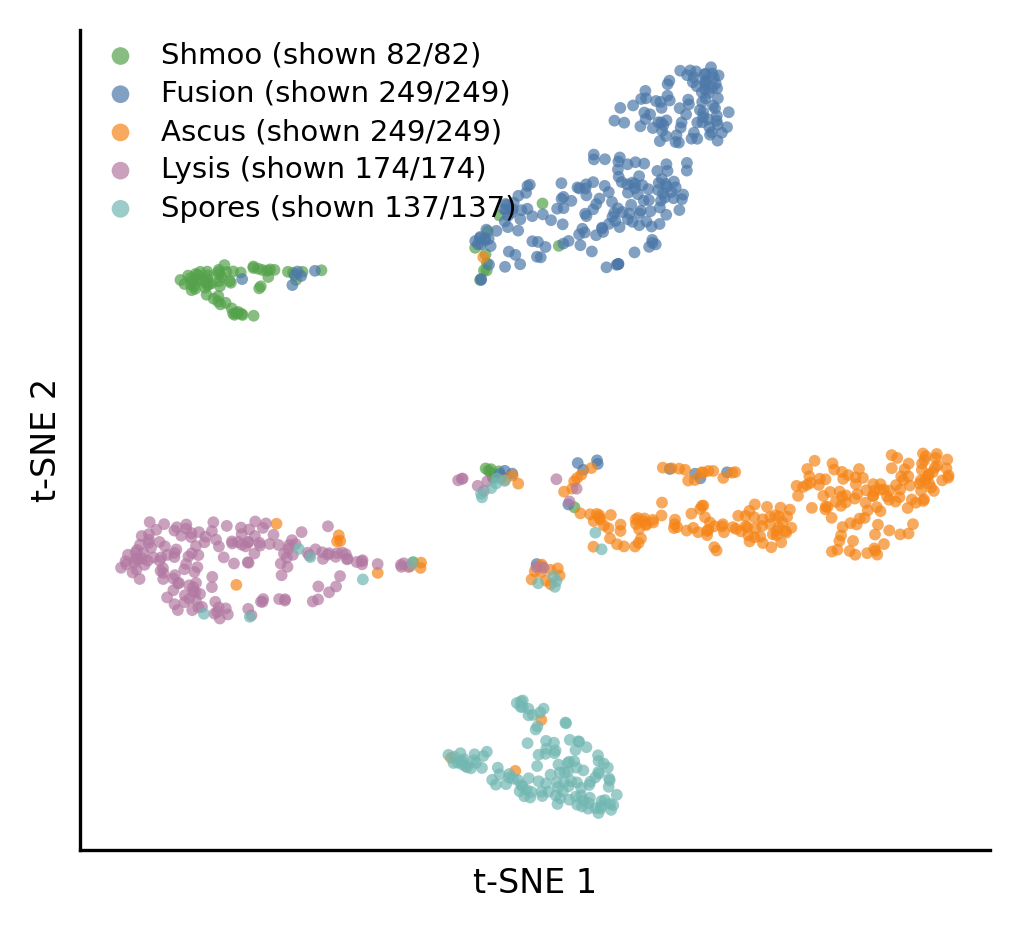

In [22]:
data_path = "./predicted_cell_embeddings.npz"
figure_path="predicted_cell_tsne.png"
perplexity=30
random_state=42

with np.load(data_path) as data:
    embeddings = data["embeddings"]
    labels = data["labels"]

embeddings = embeddings[labels>1]
labels = labels[labels>1]

if len(embeddings) < 3:
    raise ValueError("At least three cells are required for t-SNE.")

coordinates = TSNE(
    n_components=2,
    perplexity=min(perplexity, len(embeddings) - 1),
    metric="cosine",
    init="random",
    learning_rate="auto",
    random_state=random_state,
).fit_transform(embeddings)

plot_tsne(
    coordinates=coordinates,
    labels=labels,
    output_path=figure_path,
    cutoff_number=None,
    class_ids=np.unique(labels),
)

In [15]:
import pickle
import pandas as pd
with open("contrast_embedding_selected_3ch_crop512_test_10001_10130.pkl", "wb") as f:
    pickle.dump(results, f)

In [79]:
tsne_coordinates = calculate_tsne(
    results["embeddings"],
    perplexity=60,
    random_state=1,
)

Running t-SNE: samples=7368, dimensions=32, perplexity=60


In [80]:
import pandas as pd
tsne_results = pd.DataFrame({
    "tsne_1": tsne_coordinates[:, 0],
    "tsne_2": tsne_coordinates[:, 1],
    "label": results["labels"],
    "image_names": results["image_names"],
    "panoptic_ids": results["panoptic_ids"],
})

tsne_results.to_csv("tsne_results_3ch_crop512_test_10001_10130.pkl.csv", index=False)


(<Figure size 1050x960 with 1 Axes>,
 <Axes: xlabel='t-SNE 1', ylabel='t-SNE 2'>)

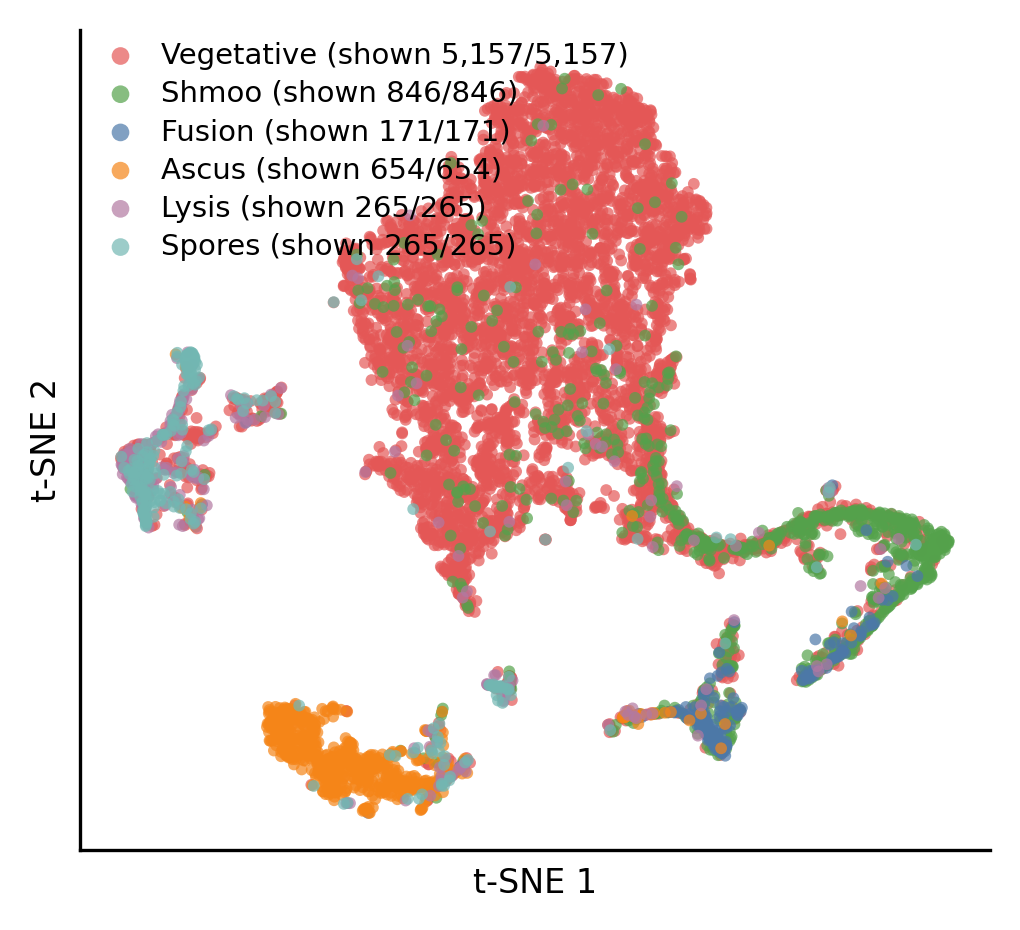

In [81]:
plot_tsne(
    coordinates=tsne_coordinates,
    labels=results["labels"],
    output_path="contrast_embedding.png",
    cutoff_number=None,
)

(<Figure size 1050x960 with 1 Axes>,
 <Axes: xlabel='t-SNE 1', ylabel='t-SNE 2'>)

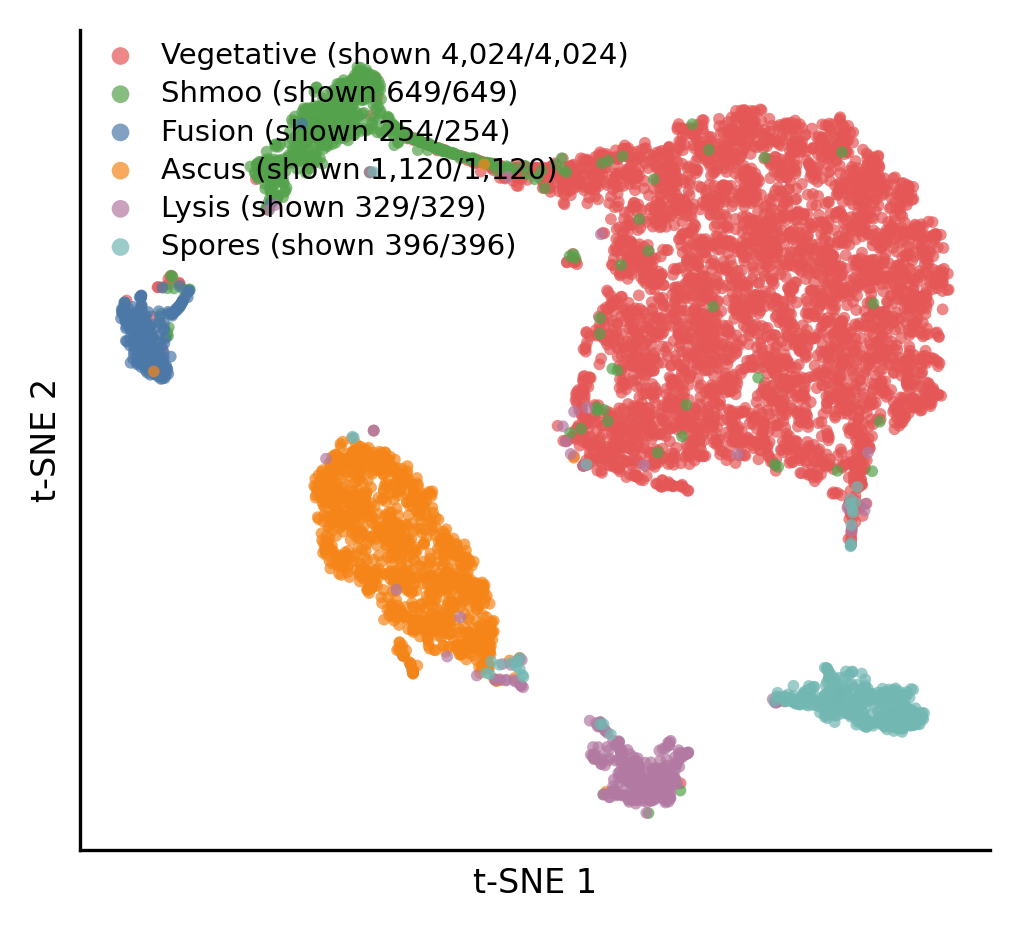

In [21]:
plot_tsne(
    coordinates=tsne_coordinates,
    labels=results["labels"],
    output_path="contrast_embedding.png",
    cutoff_number=None,
)

(<Figure size 1050x960 with 1 Axes>,
 <Axes: xlabel='t-SNE 1', ylabel='t-SNE 2'>)

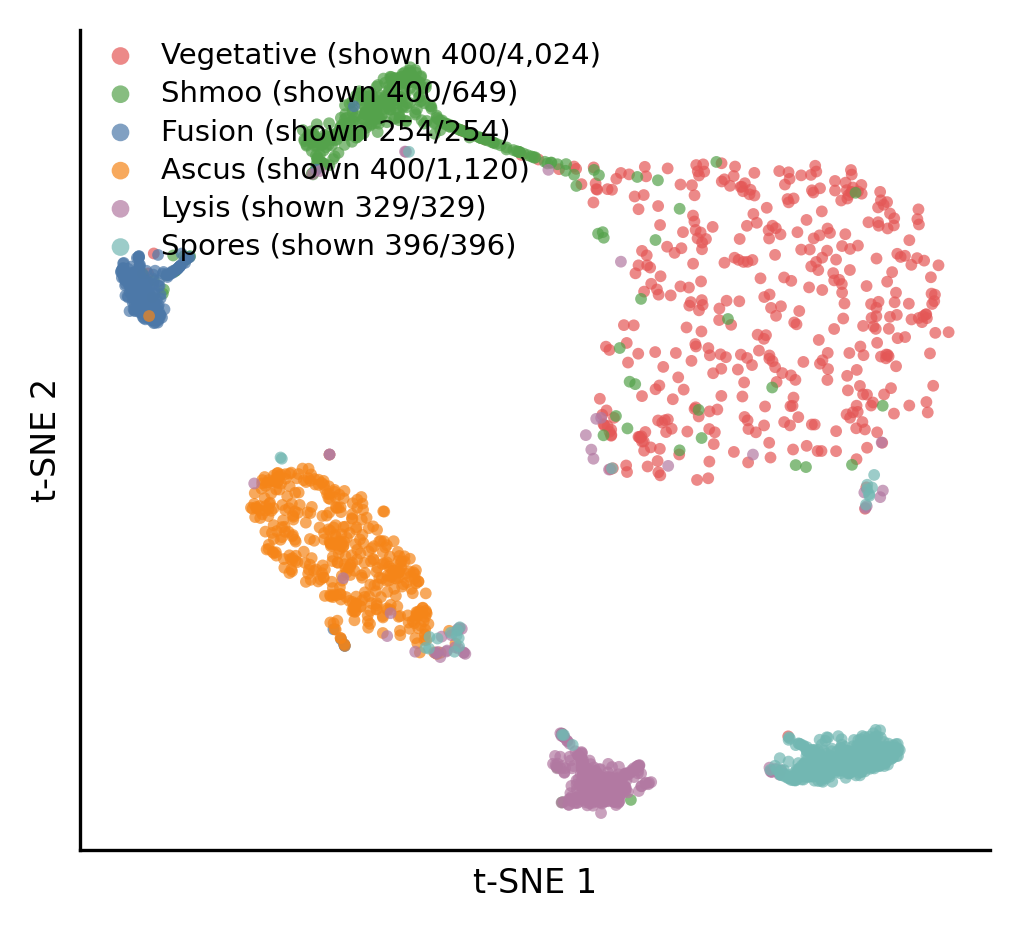

In [14]:
plot_tsne(
    coordinates=tsne_coordinates,
    labels=results["labels"],
    output_path=OUTPUT_FIGURE,
    cutoff_number=400,
)

(<Figure size 1050x960 with 1 Axes>,
 <Axes: xlabel='t-SNE 1', ylabel='t-SNE 2'>)

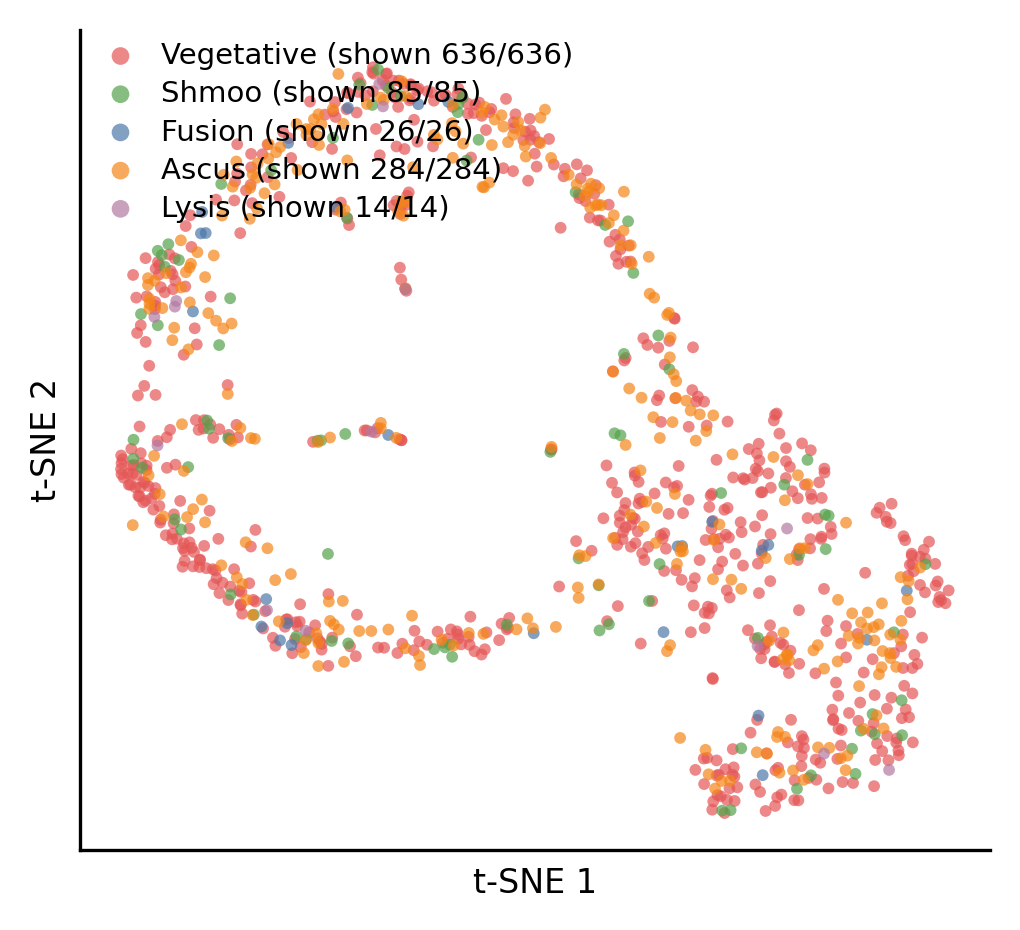

In [51]:
plot_tsne(
    coordinates=tsne_coordinates,
    labels=results["labels"],
    output_path=OUTPUT_FIGURE,
    cutoff_number=None,
)

In [44]:
class_id = 2
plt.scatter(tsne_coordinates[results["labels"]==class_id, 0], tsne_coordinates[results["labels"]==class_id, 1])
seletcted = (results["labels"]==class_id)&((tsne_coordinates[:, 0]<0))
plt.scatter(tsne_coordinates[seletcted, 0], tsne_coordinates[seletcted, 1])

NameError: name 'plt' is not defined

In [349]:
table = pd.DataFrame([results['image_names'][seletcted],results['panoptic_ids'][seletcted]]).T
table.columns=["image_id", "p_id"]
table

,image_id,p_id
0,00004_leftImg8bit_top_right.png,2257
1,00087_leftImg8bit_top_right.png,2045
2,00245_leftImg8bit_top_right.png,2020
3,00247_leftImg8bit_top_left.png,2014
4,00251_leftImg8bit_bottom_right.png,2019
5,00391_leftImg8bit_bottom_left.png,2235
6,00403_leftImg8bit_bottom_left.png,2106
7,00422_leftImg8bit_top_right.png,2125
8,00475_leftImg8bit_bottom_left.png,2002
9,00497_leftImg8bit_bottom_left.png,2010


In [350]:
np.unique(table.image_id)

array(['00004_leftImg8bit_top_right.png',
       '00087_leftImg8bit_top_right.png',
       '00245_leftImg8bit_top_right.png',
       '00247_leftImg8bit_top_left.png',
       '00251_leftImg8bit_bottom_right.png',
       '00391_leftImg8bit_bottom_left.png',
       '00403_leftImg8bit_bottom_left.png',
       '00422_leftImg8bit_top_right.png',
       '00475_leftImg8bit_bottom_left.png',
       '00497_leftImg8bit_bottom_left.png',
       '00512_leftImg8bit_top_right.png',
       '10073_leftImg8bit_top_right.png',
       '10075_leftImg8bit_top_right.png',
       '10078_leftImg8bit_top_right.png',
       '10081_leftImg8bit_bottom_left.png'], dtype=object)

[2051]


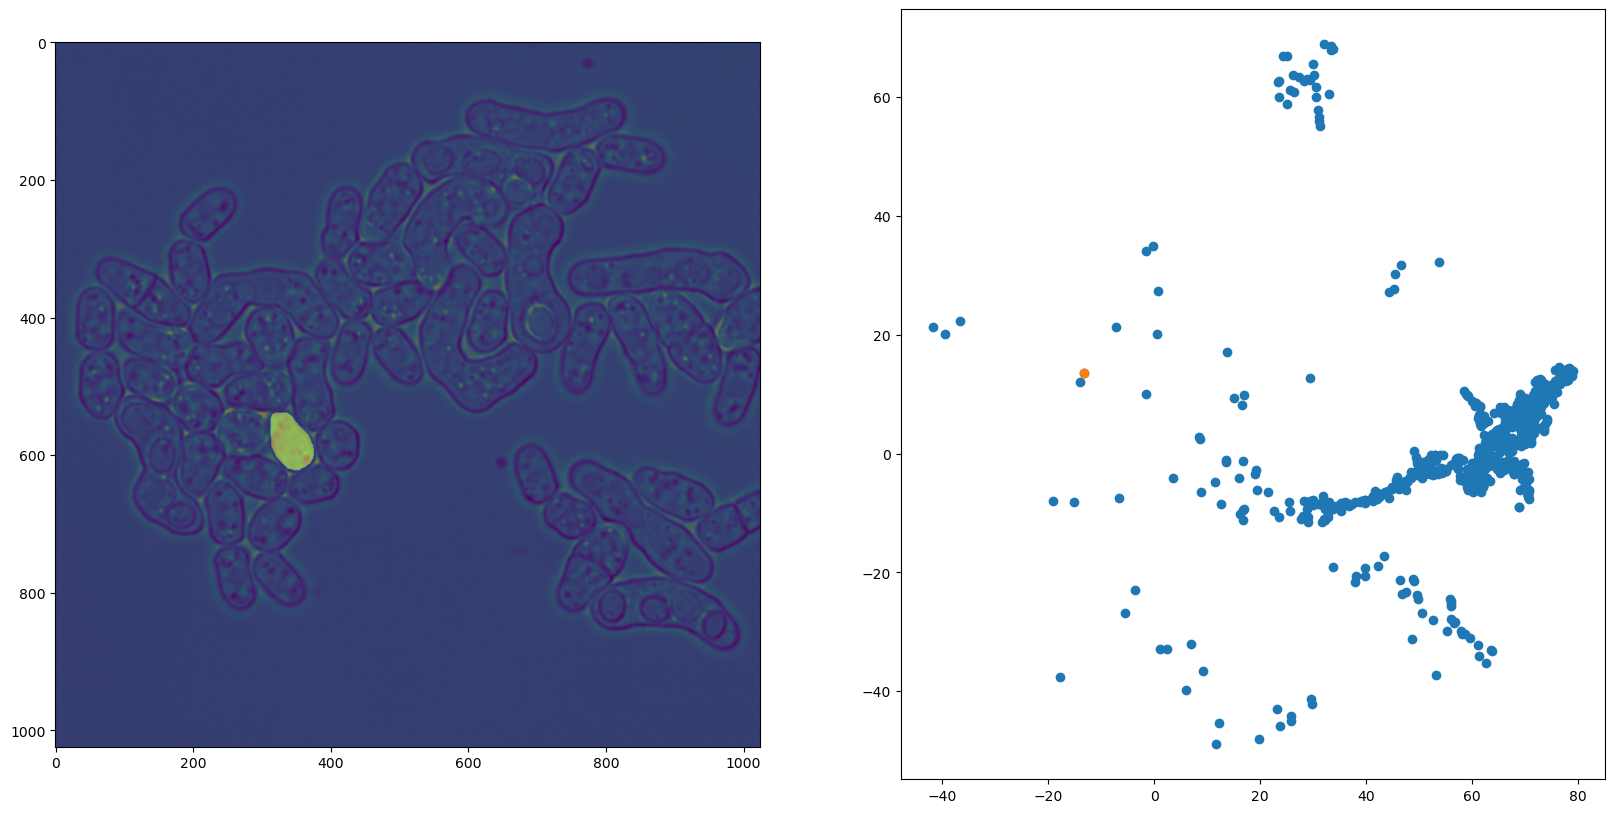

In [366]:
selected_name = "10081_leftImg8bit.png"
original_names = table["image_id"].map(get_original_name)
selected_rows = table[original_names == selected_name]
p_ids = selected_rows["p_id"].dropna().astype(int).unique()
print(p_ids)
# image = imread("/home/liwa/data/datasets/yeastcity/gtFine/train/0601_0700/"+selected_name[0:5]+"_gtFine_instanceIds.png")
# image_bg = imread("/home/liwa/data/datasets/yeastcity/leftImg8bit/train/0601_0700/"+selected_name[0:5]+"_leftImg8bit.png")
image = imread("./contrast_gt/"+selected_name[0:5]+"_gtFine_instanceIds.png")
image_bg = imread("./contrast_image/"+selected_name[0:5]+"_leftImg8bit.png")
fig ,axs = plt.subplots(1, 2, figsize=(20,10))
axs[0].imshow(image_bg[:,:,0])
axs[0].imshow(np.isin(image, p_ids), alpha=0.5)

axs[1].scatter(tsne_coordinates[results["labels"]==class_id, 0], tsne_coordinates[results["labels"]==class_id, 1])
seletcted_image = seletcted &(np.char.startswith(results["image_names"].astype(str), selected_name[:5]))

axs[1].scatter(tsne_coordinates[seletcted_image, 0], tsne_coordinates[seletcted_image, 1])

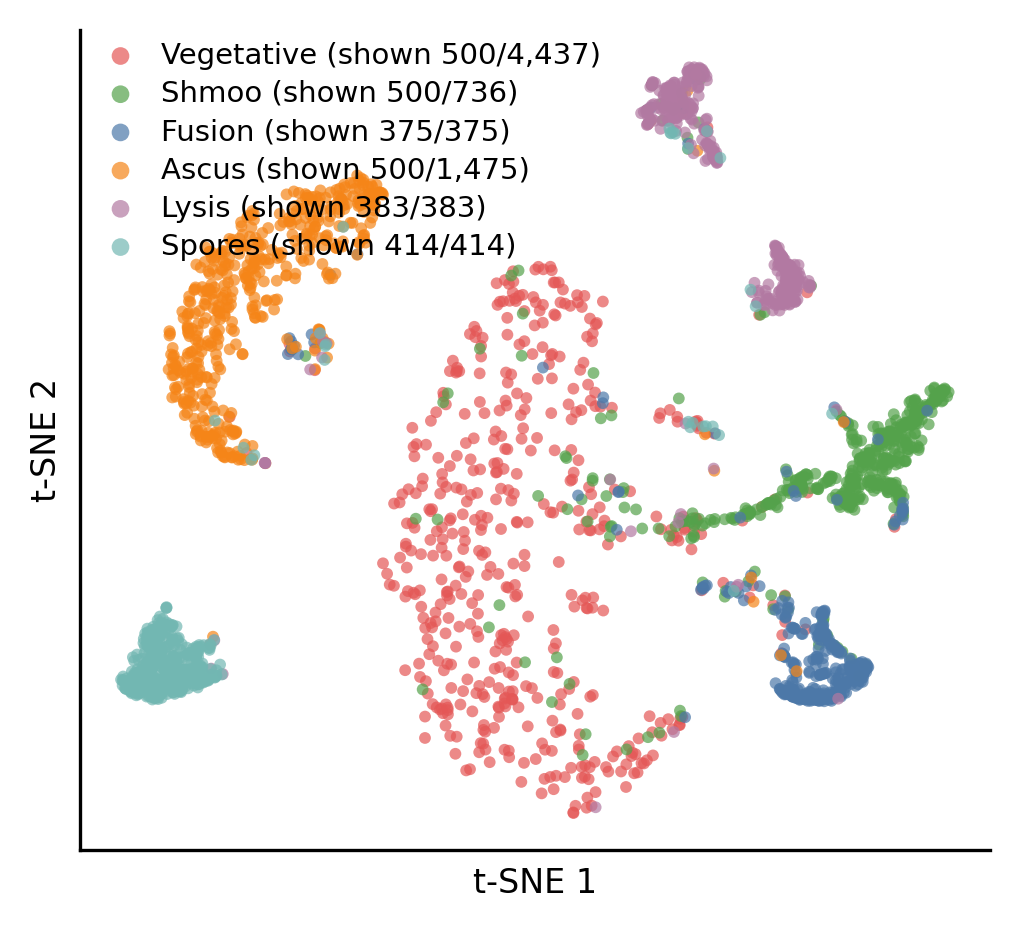

In [345]:
fig, ax = plot_tsne(
    coordinates=tsne_coordinates,
    labels=results["labels"],
    output_path=OUTPUT_FIGURE,
)

(<Figure size 1050x960 with 1 Axes>,
 <Axes: xlabel='t-SNE 1', ylabel='t-SNE 2'>)

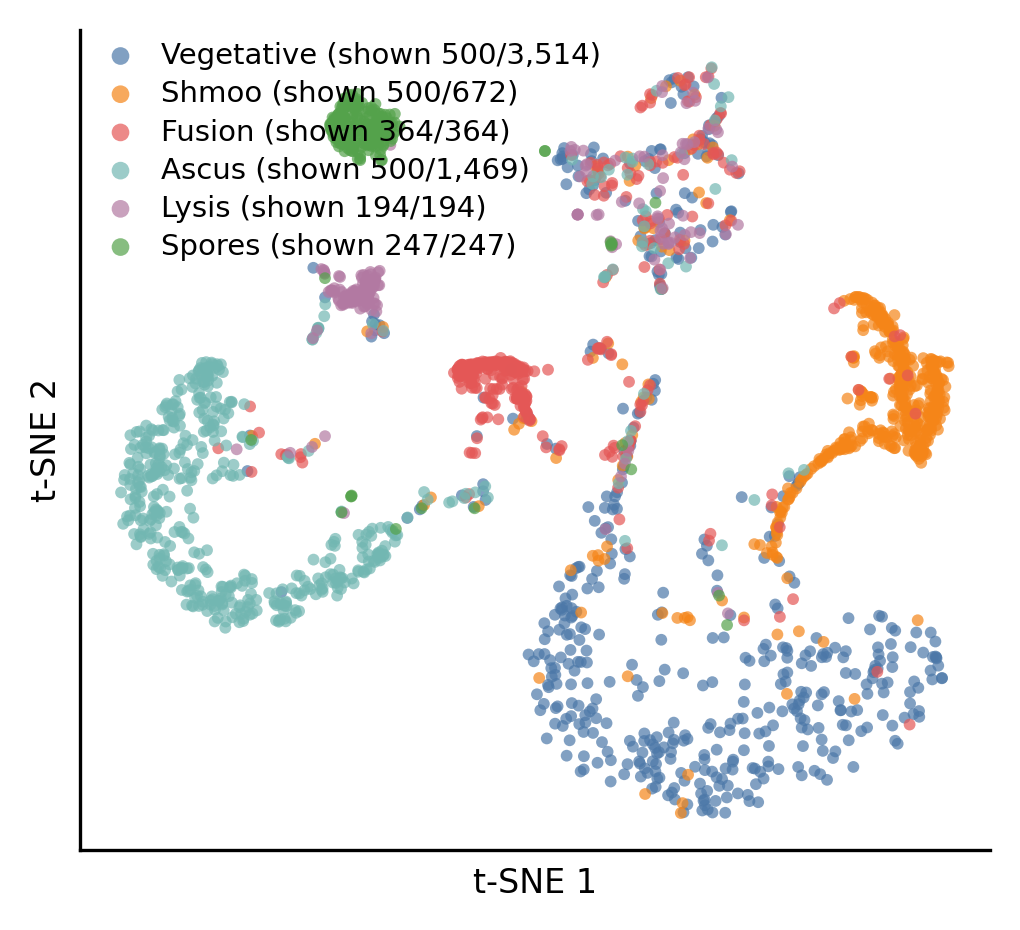

In [14]:
from contrast_learning import crop_image_and_mask
import matplotlib.pyplot as plt

In [15]:
import numpy as np


def touches_border(binary_mask, border_width=10):
    return (
        binary_mask[:border_width, :].any()
        or binary_mask[-border_width:, :].any()
        or binary_mask[:, :border_width].any()
        or binary_mask[:, -border_width:].any()
    )


def get_crop_starts(length, crop_size, stride):
    """
    Generate crop starting positions while ensuring that the
    final crop reaches the image boundary.
    """
    if length <= crop_size:
        return [0]

    starts = list(range(0, length - crop_size + 1, stride))

    final_start = length - crop_size

    if starts[-1] != final_start:
        starts.append(final_start)

    return starts


def crop_image_and_mask(
    image,
    mask,
    crop_size=512,
    overlap=64,
    border_width=10,
    background_id=0,
):
    """
    Split an image and instance mask into overlapping square crops.

    For each instance:
    1. Find all crops containing the instance.
    2. Exclude crops where the instance touches the crop border.
    3. Among the remaining crops, keep the instance only in the
       crop containing its largest visible area.
    4. If it touches the border in every crop, remove it completely.

    Parameters
    ----------
    image : ndarray
        Shape (H, W) or (H, W, C).
    mask : ndarray
        Integer instance mask with shape (H, W).
    crop_size : int
        Crop width and height.
    overlap : int
        Overlap between adjacent crops in pixels.
    border_width : int
        Border region used to identify incomplete instances.
    background_id : int
        Background value in the mask.

    Returns
    -------
    crops : dict
        Dictionary containing cropped images, cleaned masks
        and original-image positions.
    """
    height, width = mask.shape[:2]

    if image.shape[:2] != mask.shape[:2]:
        raise ValueError(
            f"Image and mask dimensions do not match: "
            f"{image.shape[:2]} versus {mask.shape[:2]}"
        )

    if overlap < 0 or overlap >= crop_size:
        raise ValueError(
            "overlap must satisfy: 0 <= overlap < crop_size"
        )

    if height < crop_size or width < crop_size:
        raise ValueError(
            f"Image size {(height, width)} is smaller than "
            f"crop size {crop_size}. Padding would be required."
        )

    stride = crop_size - overlap

    y_starts = get_crop_starts(
        height,
        crop_size,
        stride,
    )
    x_starts = get_crop_starts(
        width,
        crop_size,
        stride,
    )

    crops = {}

    # Create all crops
    for row_index, y0 in enumerate(y_starts):
        for column_index, x0 in enumerate(x_starts):
            y1 = y0 + crop_size
            x1 = x0 + crop_size

            crop_name = (
                f"row_{row_index:02d}_col_{column_index:02d}"
            )

            crops[crop_name] = {
                "image": image[y0:y1, x0:x1].copy(),
                "mask": mask[y0:y1, x0:x1].copy(),
                "position": (y0, x0),
            }

    instance_ids = np.unique(mask)
    instance_ids = instance_ids[
        instance_ids != background_id
    ]

    for instance_id in instance_ids:
        crop_information = {}

        # Check the instance in every crop
        for crop_name, crop_data in crops.items():
            region = crop_data["mask"] == instance_id
            area = int(region.sum())

            if area == 0:
                continue

            crop_information[crop_name] = {
                "area": area,
                "touches_border": touches_border(
                    region,
                    border_width,
                ),
            }

        # Crops where the instance is not cut by the border
        valid_crops = {
            crop_name: information
            for crop_name, information
            in crop_information.items()
            if not information["touches_border"]
        }

        if valid_crops:
            # Keep the largest complete occurrence
            best_crop_name = max(
                valid_crops,
                key=lambda name: valid_crops[name]["area"],
            )
        else:
            # The instance is incomplete in every crop
            best_crop_name = None

        # Remove all redundant or incomplete occurrences
        for crop_name, crop_data in crops.items():
            if crop_name != best_crop_name:
                crop_data["mask"][
                    crop_data["mask"] == instance_id
                ] = background_id

    return crops

In [26]:
mask = imread("./contrast_gt/00001_gtFine_instanceIds.png")
image = imread("./contrast_image/00001_leftImg8bit.png")
mask.shape

(2040, 2040)

In [27]:
import matplotlib.pyplot as plt

In [28]:
image.shape

(2040, 2040, 3)

In [59]:
crops = crop_image_and_mask(image, mask,     crop_size=512, overlap=200,)

In [60]:
len(crops.keys())

36

3085
1190
4099
4101
4103
4104
2223
4114
5177
4115
4116
4117
4138
10230
4135
4126
1215
1219
4146
4147
4153
4149
4150
0
4154
4164
4158
4157
4162
4165
4168
4169
4172
1070
4170
4124


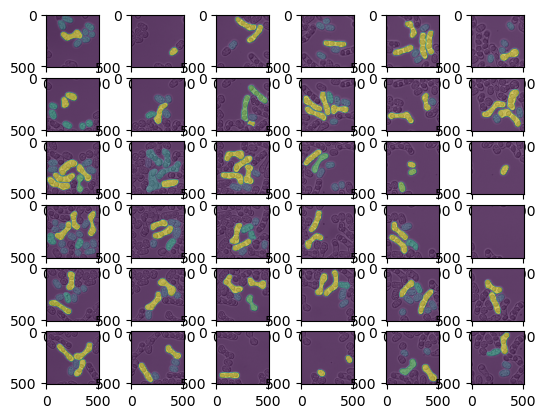

In [61]:
fig ,axs = plt.subplots(6,6)
axs = axs.ravel()
i = 0
for k, v in crops.items():
    axs[i].imshow(v["image"])
    axs[i].imshow(v["mask"], alpha=0.5)
    print(v["mask"].max())
    i+=1

In [43]:
import matplotlib.pyplot as plt
from pathlib import Path
IMAGE_FOLDER = "/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/"
MASK_FOLDER = "/home/liwa/data/datasets/yeastcity/gtFine/test/10001_10130/"

In [44]:
image_list = list(Path(IMAGE_FOLDER).rglob("*.png"))
image_list.sort()

In [45]:
image_list

[PosixPath('/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10001_leftImg8bit.png'),
 PosixPath('/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10002_leftImg8bit.png'),
 PosixPath('/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10003_leftImg8bit.png'),
 PosixPath('/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10004_leftImg8bit.png'),
 PosixPath('/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10005_leftImg8bit.png'),
 PosixPath('/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10006_leftImg8bit.png'),
 PosixPath('/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10007_leftImg8bit.png'),
 PosixPath('/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10008_leftImg8bit.png'),
 PosixPath('/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10009_leftImg8bit.png'),
 PosixPath('/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10010_leftImg8b

In [46]:
for i in image_list:
    image = imread(i)
    print(image.shape)

(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1201, 1201, 3)
(1200, 1200, 3)
(1201, 1201, 3)
(1201, 1201, 3)
(1201, 1201, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1201, 1201, 3)
(1024, 1024, 3)
(1024, 1024, 3)
(1024, 1024, 3)
(1024, 1024, 3)
(1024, 1024, 3)
(1186, 1186, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1029, 1029, 4)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(512, 512, 3)
(1199, 1199, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1200, 1200, 3)
(1199, 1199, 3)
(1140, 1140, 3)
(119

In [68]:
image = imread("/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10040_leftImg8bit.png")

In [64]:
imsave("/home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/10040_leftImg8bit.png", image[:,:,:3])

In [69]:
image.shape

(1029, 1029, 3)

In [75]:
!cp 10040_leftImg8bit.png /home/liwa/data/datasets/yeastcity/leftImg8bit/test/10001_10130/

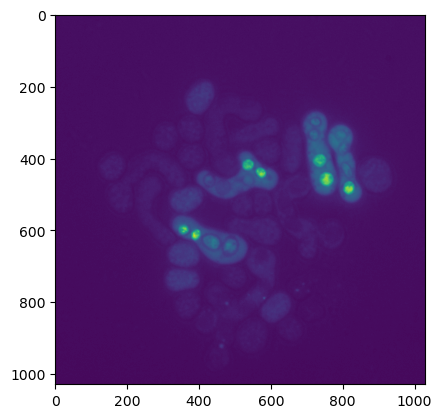

In [73]:
plt.imshow(image[:,:,2])